# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### Your answer
This project uses measurements from breast-mass images to classify each case as malignant or benign. The input consists of 30 numeric features calculated from fine-needle aspirate images, and the known labels allow a supervised learning model to be trained. Since incorrectly classifying a malignant case as benign could be serious, the model should be judged using malignant-case recall as well as overall accuracy and ROC-AUC. The final model should also be checked on data kept separate from training.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier,
                              VotingClassifier)

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df["target"] = data.target
print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [3]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes.value_counts())
display(df.head())

Shape: (569, 31)

Data types:
float64    30
int64       1
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [4]:
class_counts = y.value_counts().sort_index() if "y" in globals() else df["target"].value_counts().sort_index()
class_props = class_counts / class_counts.sum()
class_summary = pd.DataFrame({"count": class_counts, "proportion": class_props, "percent": class_props * 100})
class_summary.index = ["malignant (0)" if i == 0 else "benign (1)" for i in class_summary.index]
display(class_summary)

,count,proportion,percent
malignant (0),212,0.372583,37.258348
benign (1),357,0.627417,62.741652


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [5]:
display(df.drop(columns="target").describe().T)
skewness = df.drop(columns="target").skew().sort_values(ascending=False)
print("10 most positively skewed features:")
display(skewness.head(10))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


10 most positively skewed features:


area error                 5.447186
concavity error            5.110463
fractal dimension error    3.923969
perimeter error            3.443615
radius error               3.088612
smoothness error           2.314450
symmetry error             2.195133
compactness error          1.902221
worst area                 1.859373
worst fractal dimension    1.662579
dtype: float64

**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [6]:
target_corr = df.corr(numeric_only=True)["target"].drop("target").sort_values()
print("Five most negative correlations:")
display(target_corr.head(5))
print("Five most positive correlations:")
display(target_corr.tail(5).sort_values(ascending=False))

Five most negative correlations:


worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
Name: target, dtype: float64

Five most positive correlations:


smoothness error           0.067016
mean fractal dimension     0.012838
texture error              0.008303
symmetry error             0.006522
fractal dimension error   -0.077972
Name: target, dtype: float64

**Your answer:** The two diagnosis groups have different counts, so accuracy by itself may give an incomplete picture of model performance. Recall for malignant cases and ROC-AUC are useful additional measures. The feature summaries also show that some variables are skewed; scaling may help certain algorithms, while transformations should only be applied when they are justified by the training data and model results.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

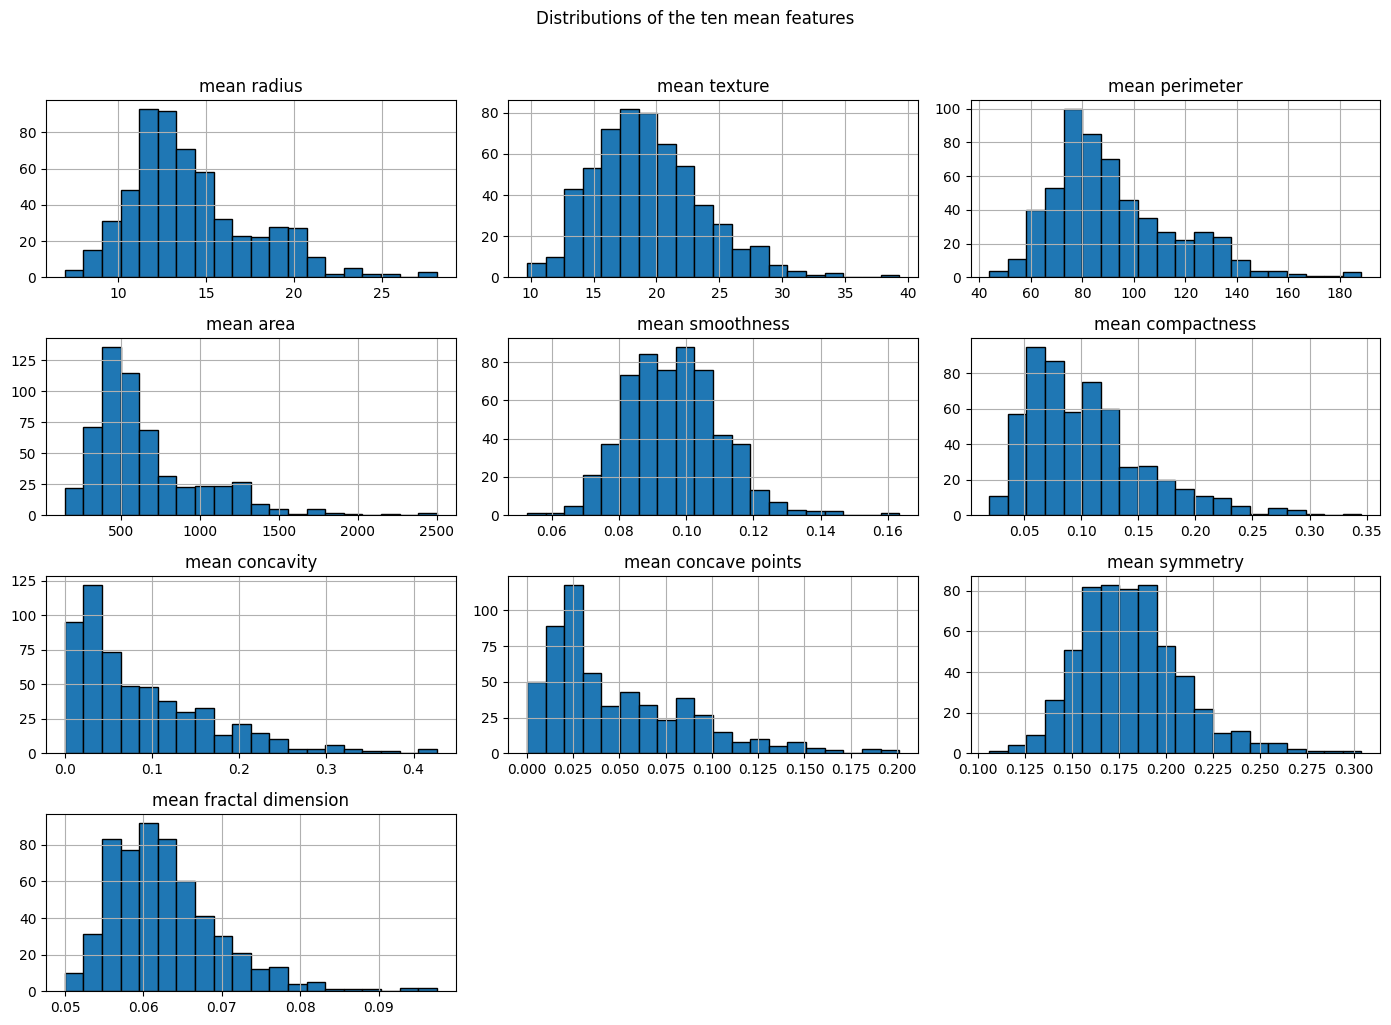

In [7]:
mean_features = df.filter(like="mean").drop(columns=[], errors="ignore")
axes = mean_features.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distributions of the ten mean features", y=1.02)
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

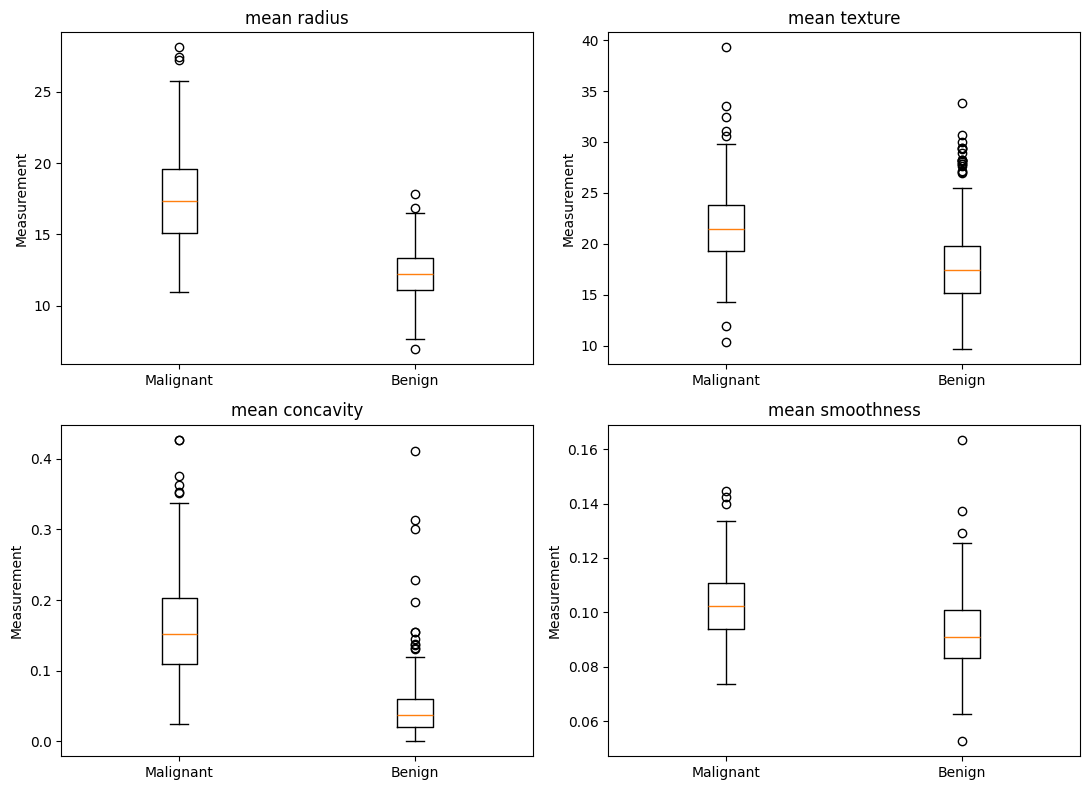

In [8]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feature in zip(axes.flat, features):
    groups = [df.loc[df["target"] == cls, feature] for cls in [0, 1]]
    ax.boxplot(groups, labels=["Malignant", "Benign"])
    ax.set_title(feature)
    ax.set_ylabel("Measurement")
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

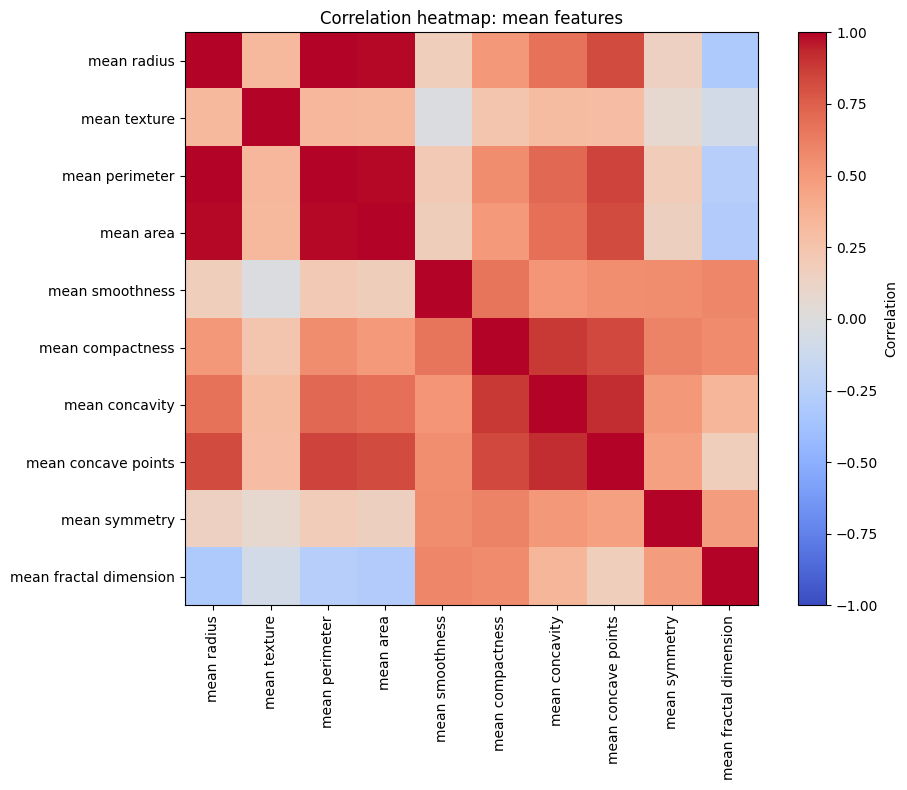

In [9]:
mean_corr = df.filter(like="mean").corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(mean_corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(mean_corr.columns)), mean_corr.columns, rotation=90)
ax.set_yticks(range(len(mean_corr.index)), mean_corr.index)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation heatmap: mean features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

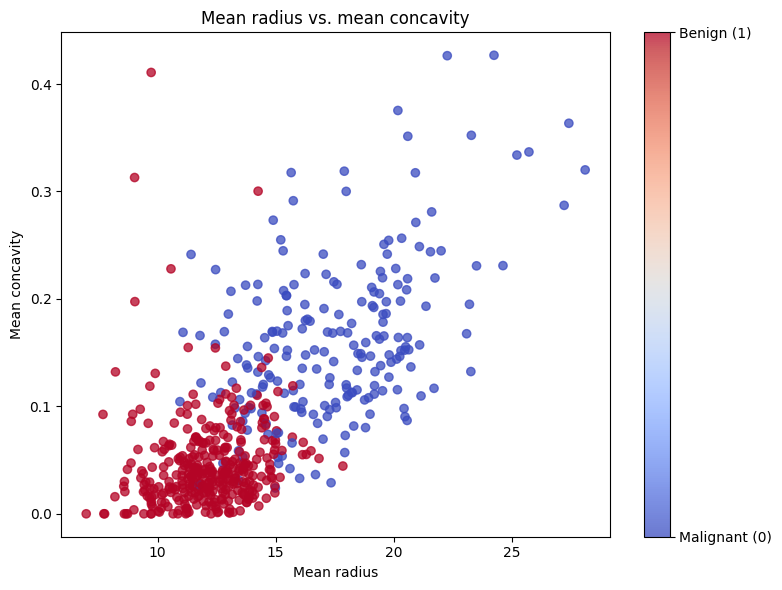

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(df["mean radius"], df["mean concavity"], c=df["target"], cmap="coolwarm", alpha=0.75)
ax.set_xlabel("Mean radius")
ax.set_ylabel("Mean concavity")
ax.set_title("Mean radius vs. mean concavity")
cbar = fig.colorbar(scatter, ax=ax, ticks=[0, 1])
cbar.ax.set_yticklabels(["Malignant (0)", "Benign (1)"])
plt.tight_layout()
plt.show()

**Your answer:** Measurements such as mean radius, mean perimeter, and mean area describe related properties of cell nuclei, so they can carry overlapping information. In the class plots, size-related measurements and concavity-related features appear useful for distinguishing the groups, although the distributions are not perfectly separated. It is better to consider several plots and correlations together than to rely on a single feature.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [11]:
print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

X = df.drop(columns="target")
y = df["target"]

Total missing values: 0
Duplicate rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [12]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1
outlier_mask = (X.lt(q1 - 1.5 * iqr)) | (X.gt(q3 + 1.5 * iqr))
outlier_counts = outlier_mask.sum().sort_values(ascending=False)
print("Ten features with the most IQR outliers:")
display(outlier_counts.head(10).to_frame("outlier_count"))

Ten features with the most IQR outliers:


,outlier_count
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
fractal dimension error,28
compactness error,28
symmetry error,27
mean area,25
worst fractal dimension,24


**Your answer:** I would first investigate outliers instead of removing them automatically. An unusually large or small measurement may be a genuine characteristic of a sample, including a malignant one. I would correct or remove a value only if there were evidence that it resulted from an error; otherwise, I would consider robust techniques or suitable transformations.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [13]:
abs_corr = X.corr().abs()
upper = abs_corr.where(np.triu(np.ones(abs_corr.shape), k=1).astype(bool))
high_corr_pairs = [(col, earlier, upper.loc[earlier, col]) for col in upper.columns
                   for earlier in upper.index if pd.notna(upper.loc[earlier, col]) and upper.loc[earlier, col] > 0.95]
high_corr_df = pd.DataFrame(high_corr_pairs, columns=["feature", "earlier_feature", "absolute_correlation"])
display(high_corr_df.sort_values("absolute_correlation", ascending=False))

,feature,earlier_feature,absolute_correlation
0,mean perimeter,mean radius,0.997855
11,worst perimeter,worst radius,0.993708
1,mean area,mean radius,0.987357
2,mean area,mean perimeter,0.986507
13,worst area,worst radius,0.984015
14,worst area,worst perimeter,0.977578
3,perimeter error,radius error,0.972794
9,worst perimeter,mean perimeter,0.970387
5,worst radius,mean radius,0.969539
6,worst radius,mean perimeter,0.969476


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [14]:
skb = SelectKBest(score_func=f_classif, k=10)
skb.fit(X, y)
skb_scores = pd.Series(skb.scores_, index=X.columns).sort_values(ascending=False)
print("Top 10 SelectKBest features:")
display(skb_scores.head(10))

Top 10 SelectKBest features:


worst concave points    964.385393
worst perimeter         897.944219
mean concave points     861.676020
worst radius            860.781707
mean perimeter          697.235272
worst area              661.600206
mean radius             646.981021
mean area               573.060747
mean concavity          533.793126
worst concavity         436.691939
dtype: float64

**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [15]:
X_standardized_for_rfe = StandardScaler().fit_transform(X)
rfe = RFE(estimator=LogisticRegression(max_iter=5000, random_state=7), n_features_to_select=10)
rfe.fit(X_standardized_for_rfe, y)
rfe_features = X.columns[rfe.support_].tolist()
print("RFE selected features:")
print(rfe_features)

RFE selected features:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

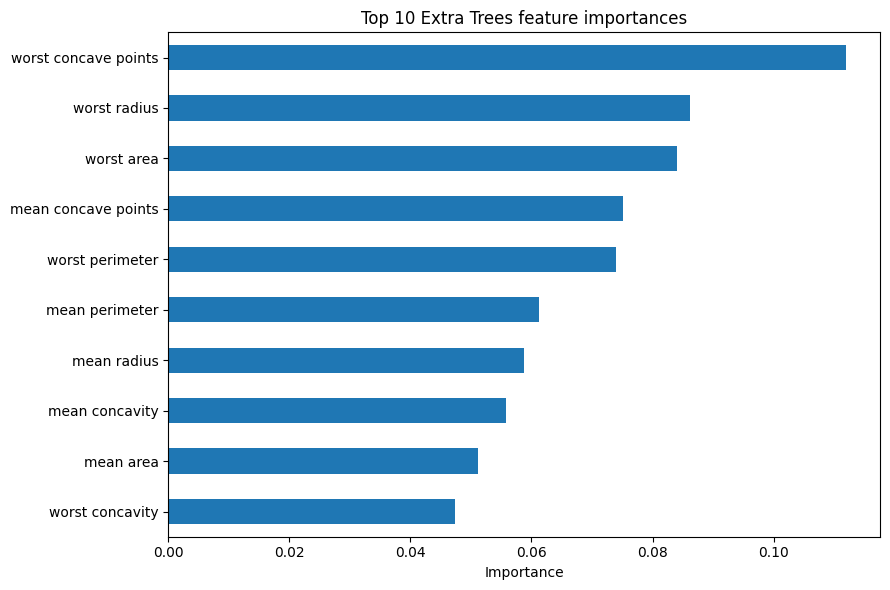

,importance
worst concave points,0.111981
worst radius,0.086108
worst area,0.083990
mean concave points,0.075045
worst perimeter,0.074022
mean perimeter,0.061303
mean radius,0.058711
mean concavity,0.055757
mean area,0.051197
worst concavity,0.047384


In [16]:
extra_trees = ExtraTreesClassifier(n_estimators=200, random_state=7)
extra_trees.fit(X, y)
imp = pd.Series(extra_trees.feature_importances_, index=X.columns).sort_values(ascending=False)
top_imp = imp.head(10).sort_values()
ax = top_imp.plot(kind="barh", figsize=(9, 6), title="Top 10 Extra Trees feature importances")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()
display(imp.head(10).to_frame("importance"))

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [17]:
skb_top = set(skb_scores.head(10).index)
rfe_set = set(rfe_features)
imp_top = set(imp.head(10).index)
selected = [feature for feature in X.columns if sum(feature in group for group in (skb_top, rfe_set, imp_top)) >= 2]
print("Selected features (at least 2 of 3 methods):", len(selected))
print(selected)

Selected features (at least 2 of 3 methods): 10
['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=7, stratify=y
)

**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [19]:
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
X_train_std = standard_scaler.fit_transform(X_train)
X_train_minmax = minmax_scaler.fit_transform(X_train)
print("StandardScaler — first four feature means and standard deviations:")
print(pd.DataFrame({"mean": X_train_std.mean(axis=0)[:4], "std": X_train_std.std(axis=0)[:4]}, index=X_train.columns[:4]).round(3))
print("\nMinMaxScaler — first four feature minima and maxima:")
print(pd.DataFrame({"min": X_train_minmax.min(axis=0)[:4], "max": X_train_minmax.max(axis=0)[:4]}, index=X_train.columns[:4]).round(3))

StandardScaler — first four feature means and standard deviations:
                mean  std
mean radius      0.0  1.0
mean texture    -0.0  1.0
mean perimeter  -0.0  1.0
mean area       -0.0  1.0

MinMaxScaler — first four feature minima and maxima:
                min  max
mean radius     0.0  1.0
mean texture    0.0  1.0
mean perimeter  0.0  1.0
mean area       0.0  1.0


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [20]:
pca = PCA().fit(X_train_std)
n_components_95 = int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), 0.95) + 1)
print("Components needed for at least 95% variance:", n_components_95)
print("Cumulative explained variance:", round(float(np.cumsum(pca.explained_variance_ratio_)[n_components_95 - 1]), 4))

Components needed for at least 95% variance: 10
Cumulative explained variance: 0.956


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [21]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

models = {
    "LR": LogisticRegression(max_iter=5000, random_state=7),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=7),
    "NB": GaussianNB(),
    "SVM": SVC(random_state=7)
}


def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy", n_jobs=-1)
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [22]:
raw_scores = spot_check(models, X_train, scale=False)
scaled_scores = spot_check(models, X_train, scale=True)
summary = pd.DataFrame({
    "raw": {name: scores.mean() for name, scores in raw_scores.items()},
    "scaled": {name: scores.mean() for name, scores in scaled_scores.items()}
}).sort_values("scaled", ascending=False)
display(summary.round(4))

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,raw,scaled
LR,0.9516,0.9823
SVM,0.8987,0.9758
KNN,0.9229,0.9649
LDA,0.9472,0.9472
NB,0.9341,0.9320
CART,0.9276,0.9276


**Your answer:** KNN is sensitive to scale because it compares distances, and SVM can also be affected because feature magnitudes influence its decision boundary. Standardizing features can help logistic regression optimize more effectively, and may also improve LDA. Tree-based models usually need no scaling because they make decisions using thresholds on individual features. Gaussian Naive Bayes is generally less sensitive to scaling than distance-based methods.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [23]:
selected_scores = spot_check(models, X_train[selected], scale=True)
selected_summary = pd.DataFrame({
    "all_features_scaled": {name: scores.mean() for name, scores in scaled_scores.items()},
    "selected_features_scaled": {name: scores.mean() for name, scores in selected_scores.items()}
})
display(selected_summary.round(4))

,all_features_scaled,selected_features_scaled
LR,0.9823,0.9604
LDA,0.9472,0.9430
KNN,0.9649,0.9428
CART,0.9276,0.9210
NB,0.9320,0.9517
SVM,0.9758,0.9539


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

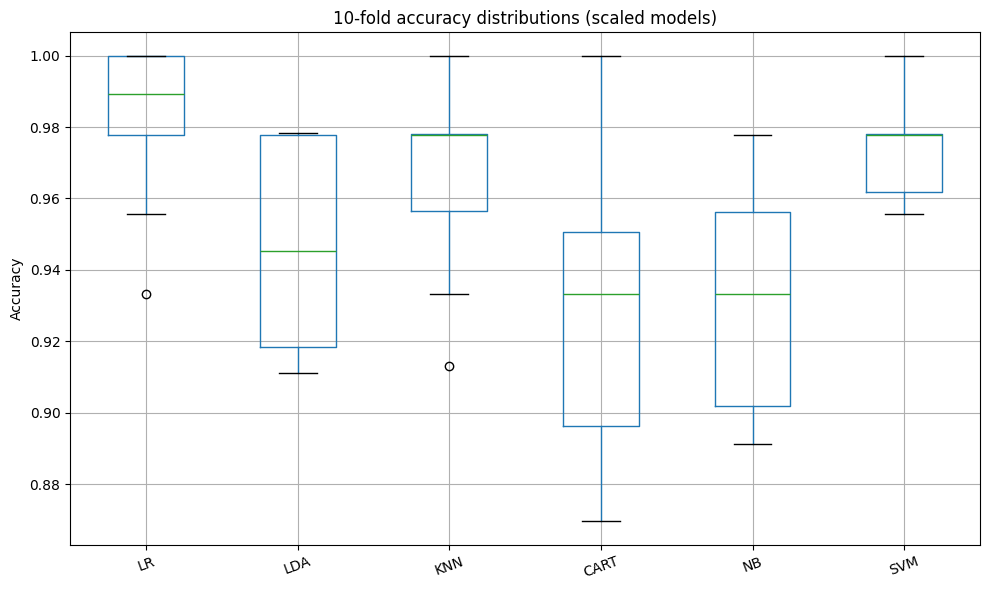

In [24]:
scaled_score_frame = pd.DataFrame(scaled_scores)
ax = scaled_score_frame.boxplot(figsize=(10, 6), rot=20)
ax.set_title("10-fold accuracy distributions (scaled models)")
ax.set_ylabel("Accuracy")
plt.tight_layout()
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [25]:
best_scaled_name = summary["scaled"].idxmax()
best_scaled_model = models[best_scaled_name]
scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "malignant_recall": make_scorer(recall_score, pos_label=0)
}
metric_results = cross_validate(
    Pipeline([("scale", StandardScaler()), ("model", best_scaled_model)]),
    X_train, y_train, cv=kfold, scoring=scoring, return_train_score=False
)
metric_summary = pd.DataFrame({metric: [metric_results[f"test_{metric}"].mean(), metric_results[f"test_{metric}"].std()]
                               for metric in scoring}, index=["mean", "std"]).T
print("Best scaled model:", best_scaled_name)
display(metric_summary.round(4))

Best scaled model: LR


,mean,std
accuracy,0.9823,0.0218
roc_auc,0.9922,0.0107
malignant_recall,0.9647,0.0471


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [26]:
svm_pipe = Pipeline([("scale", StandardScaler()), ("model", SVC())])
svm_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}
svm_search = GridSearchCV(svm_pipe, svm_grid, cv=kfold, scoring="accuracy", n_jobs=-1)
svm_search.fit(X_train, y_train)
tuned_svm = svm_search.best_estimator_
print("Best SVM parameters:", svm_search.best_params_)
print("Best SVM CV accuracy:", round(svm_search.best_score_, 4))

Best SVM parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best SVM CV accuracy: 0.9802


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [27]:
knn_pipe = Pipeline([("scale", StandardScaler()), ("model", KNeighborsClassifier())])
knn_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}
knn_search = GridSearchCV(knn_pipe, knn_grid, cv=kfold, scoring="accuracy", n_jobs=-1)
knn_search.fit(X_train, y_train)
tuned_knn = knn_search.best_estimator_
print("Best KNN parameters:", knn_search.best_params_)
print("Best KNN CV accuracy:", round(knn_search.best_score_, 4))

Best KNN parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best KNN CV accuracy: 0.9693


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [28]:
ensembles = {
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=7),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=7),
    "Gradient Boosting": GradientBoostingClassifier(random_state=7),
    "AdaBoost": AdaBoostClassifier(random_state=7)
}
ensemble_scores = spot_check(ensembles, X_train, scale=False)
voting = VotingClassifier(estimators=[
    ("svm", tuned_svm), ("knn", tuned_knn),
    ("rf", RandomForestClassifier(n_estimators=200, random_state=7))
], voting="hard")
voting_scores = cross_val_score(voting, X_train, y_train, cv=kfold, scoring="accuracy")
print("Ensemble CV accuracies:")
print({name: round(scores.mean(), 4) for name, scores in ensemble_scores.items()})
print("Voting ensemble:", round(voting_scores.mean(), 4))

Ensemble CV accuracies:
{'Random Forest': np.float64(0.9648), 'Extra Trees': np.float64(0.9714), 'Gradient Boosting': np.float64(0.967), 'AdaBoost': np.float64(0.9626)}
Voting ensemble: 0.9781


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [29]:
leaderboard_values = {
    "Tuned SVM": svm_search.best_score_,
    "Tuned KNN": knn_search.best_score_,
    **{name: scores.mean() for name, scores in ensemble_scores.items()},
    "Voting Ensemble": voting_scores.mean()
}
leaderboard = pd.Series(leaderboard_values, name="mean_cv_accuracy").sort_values(ascending=False)
display(leaderboard.to_frame().round(4))

,mean_cv_accuracy
Tuned SVM,0.9802
Voting Ensemble,0.9781
Extra Trees,0.9714
Tuned KNN,0.9693
Gradient Boosting,0.9670
Random Forest,0.9648
AdaBoost,0.9626


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Leaderboard winner: Tuned SVM
Held-out test accuracy: 0.9649

Classification report:
              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



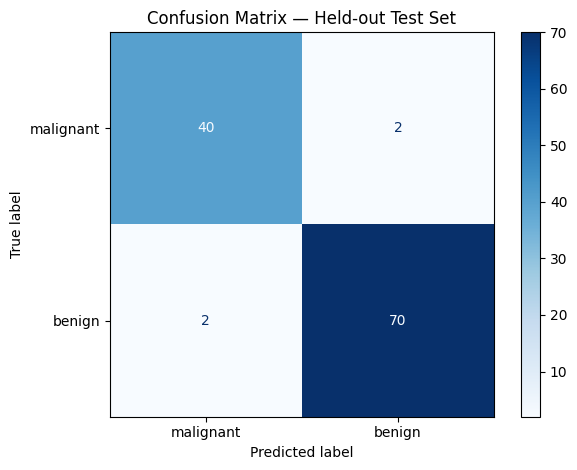

In [30]:
winner_name = leaderboard.index[0]
winner_map = {
    "Tuned SVM": tuned_svm,
    "Tuned KNN": tuned_knn,
    "Random Forest": ensembles["Random Forest"],
    "Extra Trees": ensembles["Extra Trees"],
    "Gradient Boosting": ensembles["Gradient Boosting"],
    "AdaBoost": ensembles["AdaBoost"],
    "Voting Ensemble": voting
}
winner = winner_map[winner_name]
winner.fit(X_train, y_train)
y_pred = winner.predict(X_test)
print("Leaderboard winner:", winner_name)
print("Held-out test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["malignant", "benign"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["malignant", "benign"], cmap="Blues")
plt.title("Confusion Matrix — Held-out Test Set")
plt.tight_layout()
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [31]:
import joblib
model_path = "wisconsin_breast_cancer_model.joblib"
joblib.dump(winner, model_path)
reloaded_model = joblib.load(model_path)
reloaded_predictions = reloaded_model.predict(X_test)
print("Saved model:", model_path)
print("Predictions match after reload:", np.array_equal(y_pred, reloaded_predictions))
print("First five actual labels:", y_test.iloc[:5].tolist())
print("First five predictions:", reloaded_predictions[:5].tolist())

Saved model: wisconsin_breast_cancer_model.joblib
Predictions match after reload: True
First five actual labels: [0, 0, 1, 0, 1]
First five predictions: [0, 0, 1, 0, 1]


---
## Reflection Questions

1. **Leakage.** Selecting features before cross-validation means information from all samples can influence the feature set, including samples later used for validation. This can make the estimated score too optimistic. A better approach is to place feature selection and the classifier in one pipeline, so each fold chooses features using only its own training split.

2. **Metric choice.** I would include malignant-class recall, ROC-AUC, specificity, and accuracy in the report. Recall is especially important because a malignant case predicted as benign is a false negative and may delay further medical assessment. Accuracy alone does not show which type of mistake the model makes.

3. **Model choice.** If the cross-validation accuracy of two models differs by just 0.3%, I would check their variability across folds and compare their malignant recall before deciding. When their performance is nearly equal, I would prefer the model that is easier to explain and maintain, provided its safety-relevant metrics are acceptable. The test set should be reserved for one final evaluation.

4. **Scaling.** Scaling is important for methods that use distances, margins, or optimization affected by feature magnitude, such as KNN and SVM. Tree models generally do not require it because their split rules are based on thresholds. Any scaler must be fitted on training data only to prevent information from the test set leaking into training.

5. **Limitations.** This dataset is a useful learning example, but strong results here do not prove that a model is ready for clinical use. It may not represent all hospitals, equipment, or patient populations, and false predictions can have serious consequences. A real system would need external validation, careful monitoring, expert oversight, and appropriate clinical and regulatory review.